In [1]:
# Instala o pacote (editable) no venv do projeto — rode antes dos imports.
# O kernel deste notebook é o do venv do projeto; um pip install em outro
# ambiente não é visível aqui.
!uv pip install -q -e ../Timestral

In [57]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from timestral import TimestralForecaster

In [4]:
caminho_do_checkpoint = "/home/arick/Projects/ehc-demand-forecast/Timestral/weigts"

forecaster = TimestralForecaster.from_pretrained(caminho_do_checkpoint) 

In [65]:
ehc = pd.read_excel("../data/Dados Demanda Ciclo Otto 8-3009.xlsx")
ehc['Unnamed: 0'] = pd.to_datetime(ehc['Unnamed: 0'])
ehc = ehc.rename(columns={'Unnamed: 0': 'Data', 
                          'Demanda Etanol Hidratado (m3)': "Etanol (m3)", 
                          'Demanda Gasolina C (m3)':'Gasolina (m3)', 
                          'Demanda Ciclo Otto (m3 gasolina equivalente)':'Ciclo Otto (m3)'})

## Produção Etano e Gasolina
prod_ehc = pd.read_excel("../data/Produção de Etanol.xlsx")
prod_ehc['Unnamed: 0'] = pd.to_datetime(prod_ehc['Unnamed: 0'])
prod_ehc = prod_ehc.rename(columns={'Unnamed: 0': 'Data'})

In [66]:
df_completo = pd.merge(ehc, prod_ehc, on='Data', how='outer')
df_completo = df_completo.sort_values('Data').reset_index(drop=True)

# dropar APENAS as linhas onde a demanda de Etanol é NaN
df_completo = df_completo.dropna(subset=['Etanol (m3)'])

df_treino = df_completo[df_completo['Data'] < '2022-01-01'].copy()
df_teste = df_completo[df_completo['Data'] >= '2022-01-01'].copy()

In [69]:
## Univariado
context = df_treino['Etanol (m3)'].to_numpy(dtype=np.float32)

forecast = forecaster.forecast(context, prediction_length=96)

forecast.quantiles.shape   
forecast.quantile_levels   
forecast.median            
forecast.quantile(0.9)   

tensor([[[1335446.8750, 1328992.5000, 1367800.2500, 1402433.6250, 1475200.5000,
          1522559.3750, 1605712.5000, 1696959.0000, 1741782.6250, 1818869.1250,
          1787735.7500, 1811785.2500, 1793798.5000, 1721357.5000, 1717835.0000,
          1742285.0000, 1774702.0000, 1808222.2500, 1876179.2500, 1961178.0000,
          1991978.0000, 2040279.1250, 1995006.0000, 1981097.8750, 1929908.1250,
          1831085.7500, 1810263.3750, 1804819.2500, 1850740.5000, 1895315.7500,
          1943715.2500, 2008098.6250, 2075750.0000, 2129534.0000, 2088724.6250,
          2071508.5000, 2030849.7500, 1922544.1250, 1895338.3750, 1908958.8750,
          1951245.6250, 1960875.3750, 2005604.0000, 2080377.0000, 2101585.2500,
          2127522.5000, 2099838.0000, 2091855.5000, 2018729.2500, 1937861.2500,
          1903750.1250, 1896687.3750, 1938095.7500, 1964223.0000, 2018257.2500,
          2093049.7500, 2141038.2500, 2189370.7500, 2145780.2500, 2148226.5000,
          2088000.1250, 2007668.2500, 19

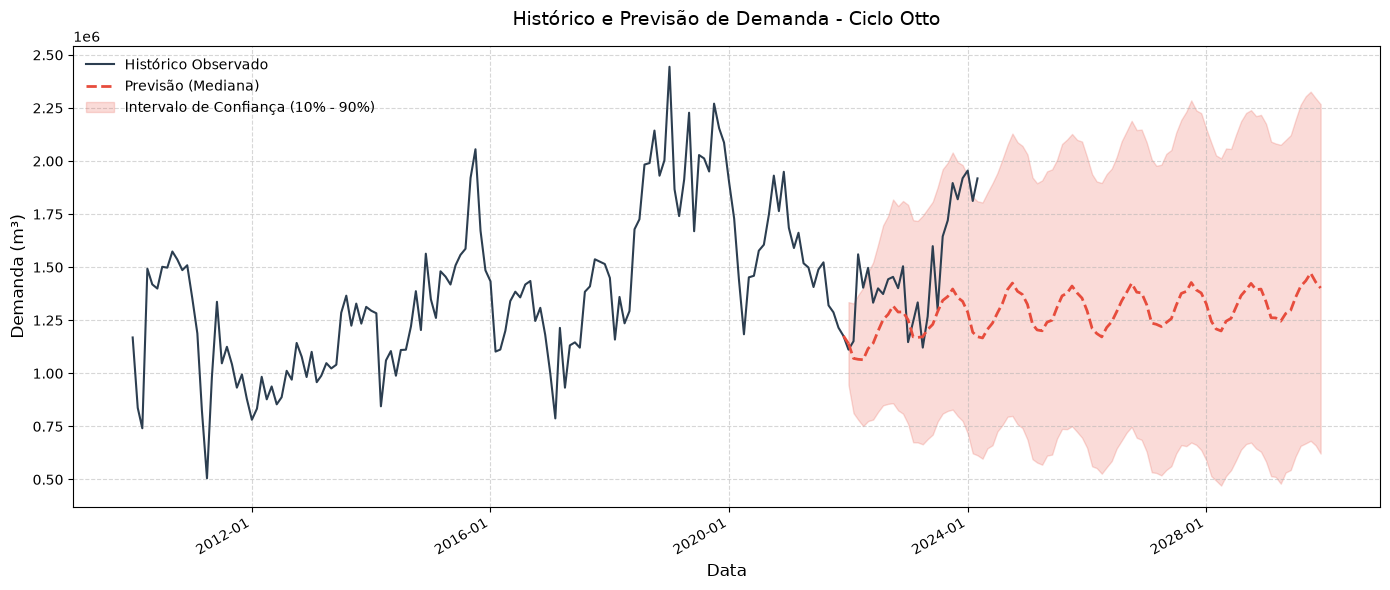

In [71]:
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import pandas as pd

# 1. Gerar as datas futuras para o eixo X (24 períodos)
ultima_data = df_treino['Data'].iloc[-1]
# 'MS' = Month Start (mensal). Use 'D' para diário ou 'W' para semanal, se necessário.
datas_futuras = pd.date_range(start=ultima_data, periods=96 + 1, freq='MS')[1:] 

# 2. Extrair as métricas da previsão do objeto forecast
# 2. Extrair as métricas do objeto forecast e "achatar" para 1D
previsao_mediana = forecast.median.flatten()
limite_inferior = forecast.quantile(0.1).flatten()
limite_superior = forecast.quantile(0.9).flatten()

# 3. Construção do gráfico com estética limpa
plt.figure(figsize=(14, 6))
plt.plot(ehc['Data'], ehc['Etanol (m3)'], 
         label='Histórico Observado', color='#2c3e50', linewidth=1.5)

# Plota a linha da mediana (forecast)
plt.plot(datas_futuras, previsao_mediana, 
         label='Previsão (Mediana)', color='#e74c3c', linewidth=2, linestyle='--')

# Plota a mancha do intervalo de confiança (P10 a P90)
plt.fill_between(datas_futuras, limite_inferior, limite_superior, 
                 color='#e74c3c', alpha=0.2, label='Intervalo de Confiança (10% - 90%)')

# Conecta o último ponto histórico ao primeiro ponto da previsão para evitar o "buraco" no gráfico
plt.plot([ultima_data, datas_futuras[0]], 
         [df_treino['Etanol (m3)'].iloc[-1], previsao_mediana[0]], 
         color='#e74c3c', linewidth=2, linestyle='--')

# Configurações de layout
plt.title('Histórico e Previsão de Demanda - Ciclo Otto', fontsize=14, pad=15)
plt.xlabel('Data', fontsize=12)
plt.ylabel('Demanda (m³)', fontsize=12)

# Formatação das datas no eixo X
plt.gca().xaxis.set_major_formatter(mdates.DateFormatter('%Y-%m'))
plt.gcf().autofmt_xdate()

# Ajustes finais da legenda e grid
plt.legend(loc='upper left', frameon=False)
plt.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()

plt.show()

In [72]:
colunas_modelo = ['Etanol (m3)', 'Gasolina (m3)', 'Ciclo Otto (m3)', 
                  'Produção de Etanol (m3)', 'Produção de Açúcar (ton)']

context_array = df_treino[colunas_modelo].fillna(0).to_numpy(dtype=np.float32)
context_array = context_array.T[np.newaxis, ...]

In [79]:
forecast = forecaster.forecast(context_array, prediction_length=96)
forecast.quantiles.shape   
forecast.quantile_levels   
forecast.median            
forecast.quantile(0.9)  

tensor([[[ 1316147.5000,  1301890.3750,  1366712.6250,  1416760.3750,
           1510367.0000,  1542519.3750,  1626924.6250,  1712353.3750,
           1700133.5000,  1788008.5000,  1715081.2500,  1747246.2500,
           1724484.5000,  1609706.1250,  1654134.2500,  1671656.5000,
           1760683.6250,  1771884.0000,  1840012.3750,  1938600.6250,
           1943958.2500,  2051902.8750,  1955433.6250,  2006453.7500,
           1949274.5000,  1798636.5000,  1865893.0000,  1835326.0000,
           1927605.7500,  1965256.3750,  2018779.8750,  2095444.2500,
           2024332.2500,  2113005.0000,  2046640.7500,  2059425.6250,
           2043798.5000,  1897642.7500,  1895959.5000,  1902353.5000,
           1967250.6250,  1952431.5000,  2024780.1250,  2103799.7500,
           2118877.5000,  2182290.5000,  2113769.0000,  2160495.0000,
           2087957.7500,  1963854.0000,  1979676.7500,  1944730.7500,
           2020259.2500,  2016182.0000,  2079256.7500,  2152311.7500,
           2183817.5

In [78]:
help(forecaster.forecast)

Help on method forecast in module timestral.forecaster:

forecast(context: torch.Tensor | numpy.ndarray, prediction_length: int, observation_mask: torch.Tensor | numpy.ndarray | None = None, past_covariates: torch.Tensor | numpy.ndarray | None = None, known_covariates: torch.Tensor | numpy.ndarray | None = None, categorical_past_covariates: torch.Tensor | numpy.ndarray | None = None, categorical_known_covariates: torch.Tensor | numpy.ndarray | None = None, symmetric_averaging: bool = True, clip_nonnegative: bool = True) -> timestral.forecaster.Forecast method of timestral.forecaster.TimestralForecaster instance
    Forecast `prediction_length` steps after `context`.

    Args:
        context: `(B, V, T)`, `(B, T)` (one variate) or `(T,)` (one series). NaN marks
            a missing value. The variates of a series are forecast jointly.
        prediction_length: Horizon in time steps.
        observation_mask: Optional boolean mask shaped like `context`; False marks
            additi

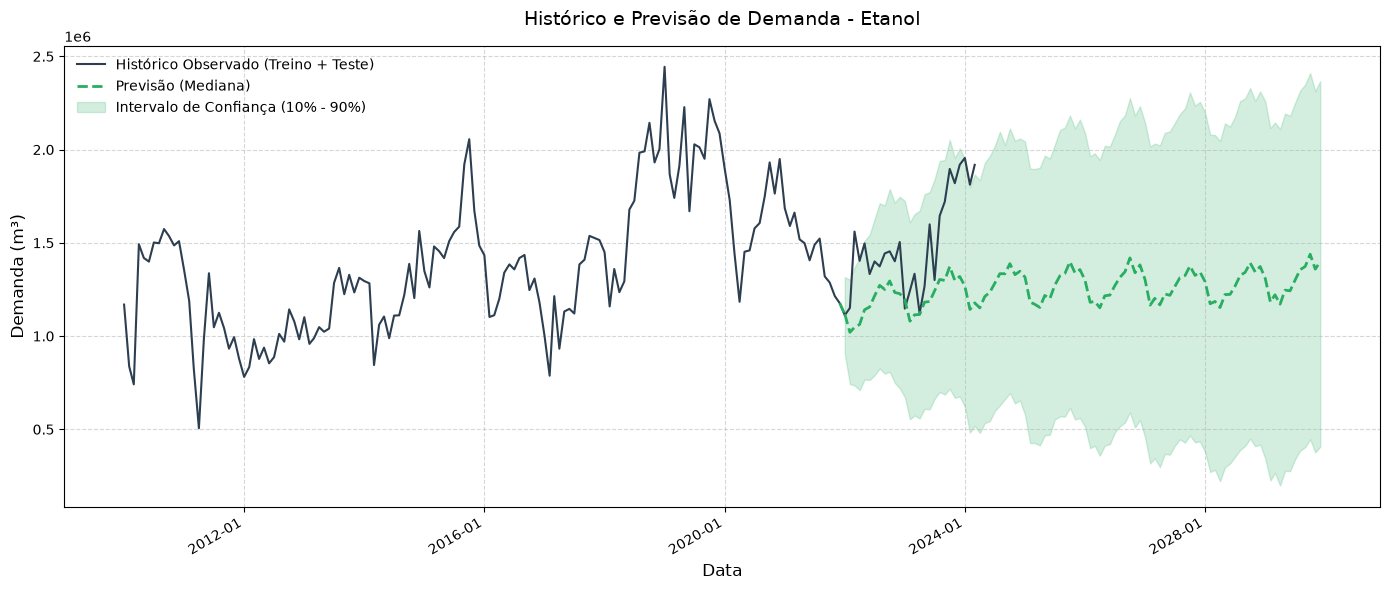

In [76]:
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import pandas as pd

# 1. Extrair os dados do Etanol (índice 0)
idx_etanol = 0
previsao_mediana = forecast.median[0, idx_etanol, :]
limite_inferior = forecast.quantile(0.1)[0, idx_etanol, :]
limite_superior = forecast.quantile(0.9)[0, idx_etanol, :]

# 2. Gerar as datas da previsão (48 meses) a partir da última data de treino
ultima_data_treino = df_treino['Data'].iloc[-1]
datas_previsao = pd.date_range(start=ultima_data_treino, periods=96 + 1, freq='MS')[1:]

# 3. Construção do gráfico
plt.figure(figsize=(14, 6))

# Plota a série histórica completa (Treino + Teste real para podermos comparar)
plt.plot(df_completo['Data'], df_completo['Etanol (m3)'], 
         label='Histórico Observado (Treino + Teste)', color='#2c3e50', linewidth=1.5)

# Plota a linha da mediana (forecast)
plt.plot(datas_previsao, previsao_mediana, 
         label='Previsão (Mediana)', color='#27ae60', linewidth=2, linestyle='--')

# Plota o intervalo de confiança
plt.fill_between(datas_previsao, limite_inferior, limite_superior, 
                 color='#27ae60', alpha=0.2, label='Intervalo de Confiança (10% - 90%)')

# Conecta o último ponto do treino ao primeiro ponto da previsão
plt.plot([ultima_data_treino, datas_previsao[0]], 
         [df_treino['Etanol (m3)'].iloc[-1], previsao_mediana[0]], 
         color='#27ae60', linewidth=2, linestyle='--')

plt.title('Histórico e Previsão de Demanda - Etanol', fontsize=14, pad=15)
plt.xlabel('Data', fontsize=12)
plt.ylabel('Demanda (m³)', fontsize=12)
plt.gca().xaxis.set_major_formatter(mdates.DateFormatter('%Y-%m'))
plt.gcf().autofmt_xdate()
plt.legend(loc='upper left', frameon=False)
plt.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()